In [129]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2
import random

%matplotlib inline

In [10]:
N = 10000

x = np.random.default_rng()
y = np.random.default_rng()

z = x.normal(size = N) + y.normal(size = N)
z

array([-0.25971693, -0.12132299, -2.12274822, ..., -0.5754164 ,
        0.36952199,  2.46267906], shape=(10000,))

In [25]:
z_std = np.std(z)
range_z = z[(z > -5 * z_std) & (z < 5 * z_std)]
x = np.linspace(min(range_z), max(range_z), N)
print(x)

[-5.39933574 -5.39829229 -5.39724884 ...  5.03206589  5.03310934
  5.0341528 ]


(array([  1.,   0.,   0.,   0.,   1.,   2.,   1.,   0.,   2.,   3.,   4.,
          3.,   4.,   6.,   2.,   6.,  12.,  15.,  17.,  13.,  18.,  29.,
         32.,  42.,  43.,  37.,  70.,  77.,  67.,  79.,  81., 119., 106.,
        115., 134., 126., 165., 172., 187., 205., 204., 232., 238., 233.,
        278., 253., 248., 293., 294., 273., 283., 295., 298., 298., 306.,
        281., 291., 267., 259., 250., 245., 241., 208., 204., 179., 167.,
        159., 148., 142., 111., 104.,  94.,  90.,  68.,  69.,  56.,  50.,
         42.,  38.,  28.,  29.,  33.,  22.,  22.,  16.,  13.,  10.,   8.,
          5.,   5.,   5.,   4.,   3.,   2.,   2.,   2.,   2.,   1.,   1.,
          2.]),
 array([-5.39933574, -5.29500086, -5.19066597, -5.08633109, -4.9819962 ,
        -4.87766132, -4.77332643, -4.66899155, -4.56465666, -4.46032178,
        -4.35598689, -4.251652  , -4.14731712, -4.04298223, -3.93864735,
        -3.83431246, -3.72997758, -3.62564269, -3.52130781, -3.41697292,
        -3.31263804, -3.20

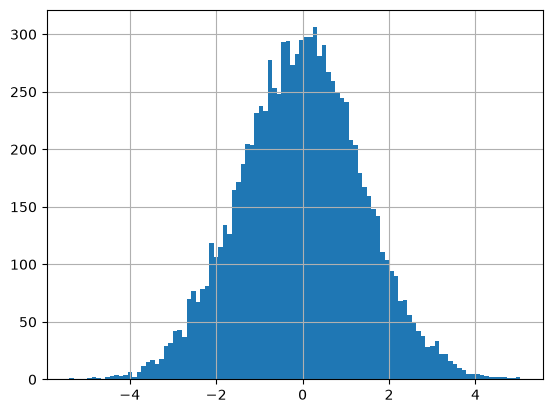

In [19]:
plt.grid()
plt.hist(range_z, bins = 100)

In [98]:
def P(z, N0, mu, sigma):
    return N0 * (1/(np.sqrt(2*np.pi) * sigma) *  np.exp(-1/2 * ((z - mu)/sigma) ** 2))


In [99]:
hist, edges = np.histogram(z, 100)
bin_centre = (1/2 * (edges[1:] - edges[:-1])) + edges[:-1]
edges.shape

(101,)

In [100]:
hist = np.array([float(x) for x in hist])
alpha = 0.158
lk = chi2.ppf(alpha, 2 * hist)
uk = chi2.ppf(1 - alpha, 2 * (hist + 1.0))/2
lk[np.isnan(lk)] = 0

In [101]:
upper = uk - hist
lower = hist - lk

delta = np.where(hist > 0, [max(x) for x in list(zip(upper, lower))], 1.84)

delta.shape


(100,)

In [102]:
pars, cov = curve_fit(P, bin_centre, hist, sigma= delta)

In [106]:
print(f"Parameters estimated : {pars} \nCovariance Matrix: \n {cov}")

Parameters estimated : [ 1.03840767e+03 -2.93839396e-02  1.40307941e+00] 
Covariance Matrix: 
 [[ 5.60376126e+01 -4.55858941e-05  5.39116775e-03]
 [-4.55858941e-05  1.13648064e-04 -4.83236626e-07]
 [ 5.39116775e-03 -4.83236626e-07  6.83405676e-05]]


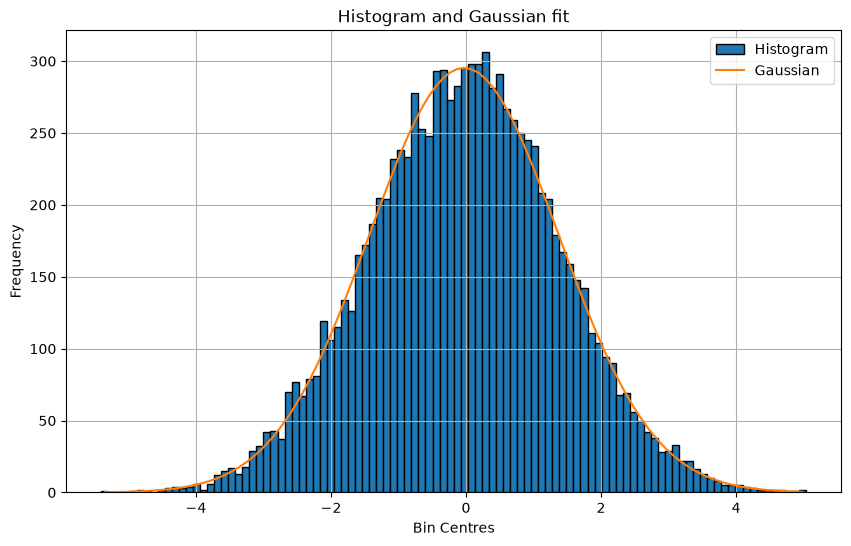

In [128]:
fig= plt.figure(figsize = (10, 6))
plt.title("Histogram and Gaussian fit")
plt.grid()
plt.hist(z, bins = 100, label = "Histogram", edgecolor = "black")
plt.plot(bin_centre, P(bin_centre, *pars), label = "Gaussian")
plt.xlabel("Bin Centres")
plt.ylabel("Frequency")
plt.legend()

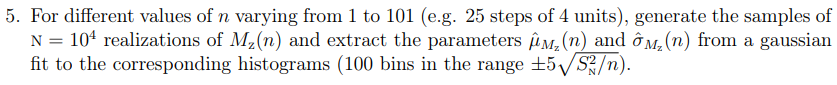

In [ ]:
n = np.random.default_rng()
N = 10000

def Mz(n):
    return 1/n * (sum(z[:n-1]))

arr = np.array([random.randint(1, 101) for x in range(10000)])
Mz = np.array([Mz(x) for x in arr])

Mz_std = np.std(Mz)
range_Mz = Mz[(Mz > -5 * Mz_std/np.sqrt())]

(10000,)

(array([104.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0., 103.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 199.,   0.,   0.,
          0.,   0., 197., 209.,   0., 308., 294., 176., 475., 193., 273.,
          0., 113., 102., 309., 209., 415., 419., 294., 483., 352., 675.,
        585., 100., 661., 707., 311., 207., 397., 114., 181.,  85., 109.,
        195.,   0.,   0.,   0., 215.,   0.,   0.,   0.,   0., 143.,   0.,
         88.]),
 array([-0.62594703, -0.61644308, -0.60693912, -0.59743517, -0.58793121,
        -0.57842725, -0.5689233 , -0.55941934, -0.54991538, -0.54041143,
        -0.53090747, -0.52140351, -0.51189956, -0.5023956 , -0.49289164,
        -0.48338769, -0.47388373, -0.46437977, -0.45487582, -0.44537186,
        -0.4358679 , -0.42

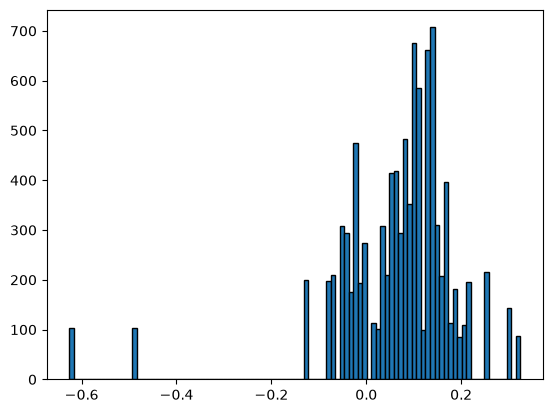

In [136]:
plt.hist(Mz, bins = 100, edgecolor = "black")